# Descriptive Mean-Reversion Research — `btcusdt@1h`

**Question (descriptive, not predictive):** how well does each mean-reversion signal — across anchors and parametrizations — *describe the current MR state*? The state has two parts: the **tension** (how far, and which side, price sits from fair value) and whether we're in a **reverting (range)** regime where that tension is expected to snap back. Which anchors describe it best, how do we **aggregate** them, and what do we **report** per instrument for the universe scan?

No forward returns — the target is the *state* itself. Plan: **(1)** define the reference MR state → **(2)** the anchor panel → **(3)** score each anchor's description → **(4)** aggregate → **(5)** report.

**Horizon.** Mean-reversion is a *short*-horizon phenomenon, so we run on **1-hour bars** with short anchors (6–48h) and define reversals as turns over **±8 bars (~8h)** — not the multi-week swings a daily study would pick up.

In [1]:
import sys
sys.path[:0] = ['C:\\Users\\SamuelAhou\\Documents\\operator', 'C:\\Users\\SamuelAhou\\Documents\\operator\\research\\mean_reversion']
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import descriptive_lib as D
from src.signals import state
SPEC = {'label': 'btcusdt@1h', 'kind': 'bars', 'asset_type': 'perps', 'source': 'binance', 'symbol': 'btcusdt', 'timeframe': '1h', 'asset_class': 'crypto'}
# 1h config: anchors 6-48h, centered regime ~1.5 days, reversals over +-8h, ~20-day standardizing/percentile windows.
BW = (6, 12, 24, 48)
OUW = (24, 48)
REF_WIN, MINLEN, REV_ORDER, ZWIN = 72, 24, 8, 480
ohlc = D.load_ohlc(SPEC)
close = ohlc['close']
ref = D.reference_state(close, window=REF_WIN, min_len=MINLEN)
panel = D.signal_panel(ohlc, asset_class=SPEC['asset_class'], timeframe=SPEC['timeframe'],
                       boll_windows=BW, vwap_windows=BW, ou_windows=OUW)
print(f"{SPEC['symbol']} {SPEC['timeframe']}: {len(close)} bars "
      f"{close.index.min().date()} -> {close.index.max().date()}")

btcusdt 1h: 56760 bars 2019-12-31 -> 2026-06-21


## Step 1 — Define the MR state we are describing

Two hindsight references (centered ~1.5-day window — benchmark truth, never a signal):
- **regime** ∈ {`range`, `trend`}: reuse the trend regime and read it for MR — `chop` becomes **range** (price churns, deviations should revert), a directional move becomes **trend** (deviations persist). Same de-flickered rule (hysteresis + minimum duration), scaled to the 1h horizon.
- **reference deviation**: price minus its *centered* local mean, in σ — the **true stretch** an anchor signal ought to reproduce.

Below: range (blue) / trend (orange) on price, and the reference deviation beneath.

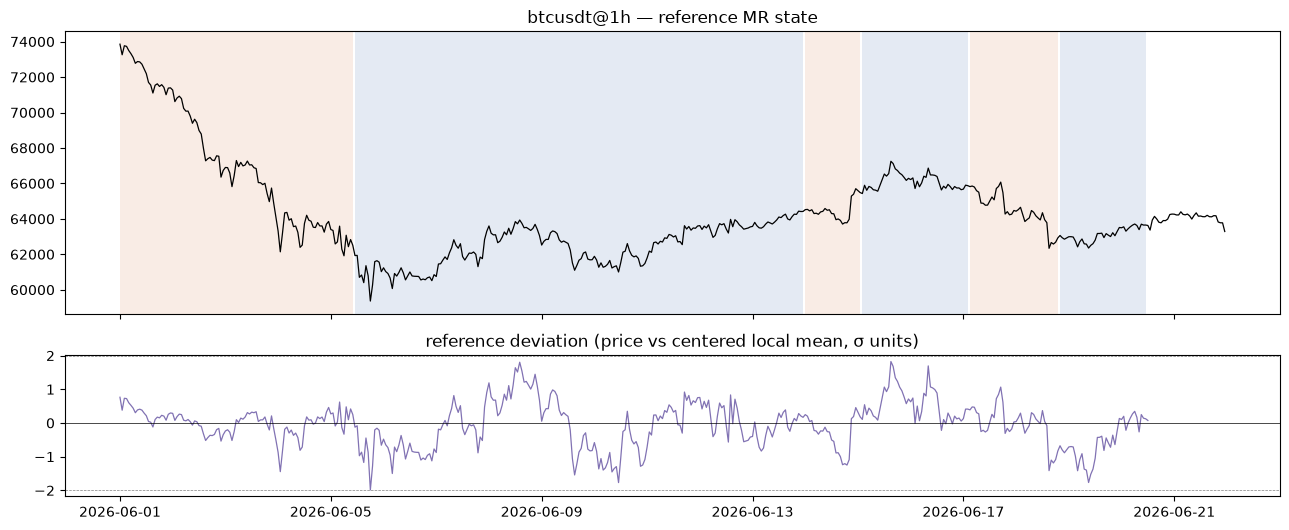

regime
range    43440
trend    13247
NaN         73
Name: count, dtype: int64

In [2]:
D.plot_reference(close, ref, f"{SPEC['label']} — reference MR state")
ref['regime'].value_counts(dropna=False)

## Step 2 — The anchor panel (families × parametrizations)

Deviation z-scores from four anchor families at short windows: **Bollinger** (6/12/24/48h), **rolling-VWAP** (6/12/24/48h), **OU s-score** (24/48h), **JASON pivot**. All causal; >0 = price rich (above the anchor), <0 = cheap. Below, a **fast (6h)** vs a **slow (48h)** Bollinger under the regime shading — watch the deviation *oscillate* (revert) in range and *drift* (persist) in trend.

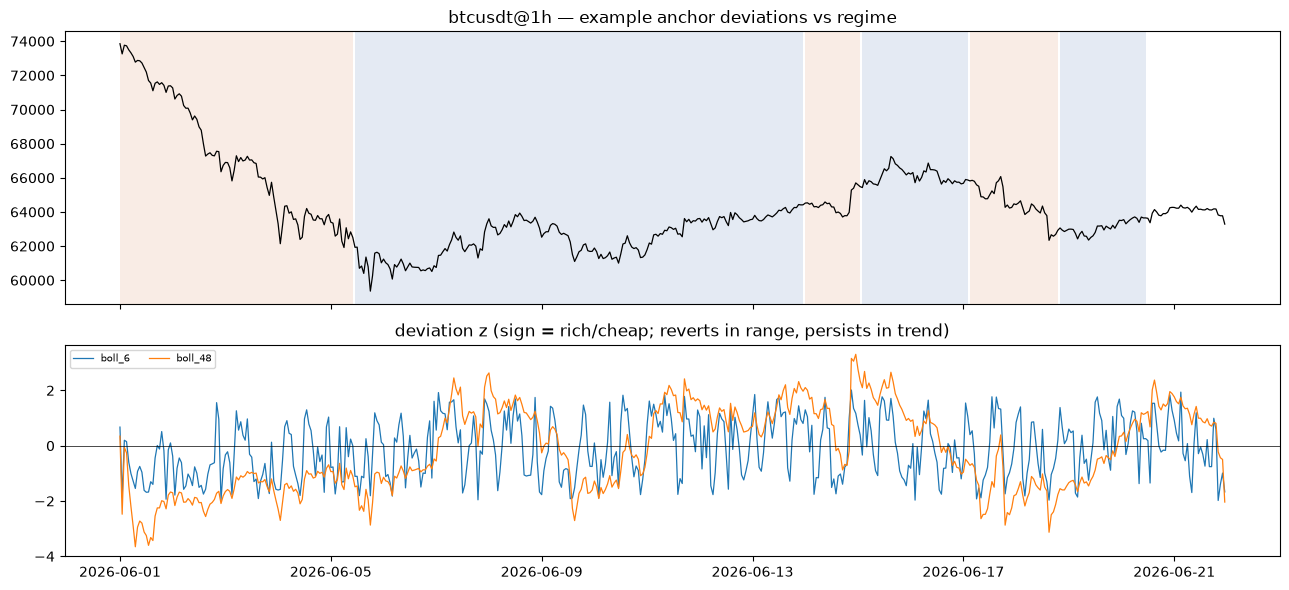

In [3]:
D.plot_signal_examples(close, panel, ref, ['boll_6', 'boll_48'],
    f"{SPEC['label']} — example anchor deviations vs regime")

## Step 3 — How well does each anchor *describe* the MR state?

Descriptive metrics (no forward returns):
- **deviation tracking (`dev_corr`)** — Spearman correlation of the anchor's z with the *true* stretch (the centered ~1.5-day deviation). Note this favours *slower* anchors simply because the reference deviation is a slower quantity — the reversal check below is the one matched to the MR horizon.
- **half-life** — OU reversion speed of the deviation (bars to snap halfway back).
- **zero-cross rate, range vs trend** — does the deviation actually *revert* (cross zero often) in range while *persisting* in trend? `zc_range ≫ zc_trend` is the signature of a faithful MR anchor.
- **flip-rate** — overall stability.

In [4]:
scores = D.score_panel(panel, ref)
scores.round(3).sort_values('dev_corr', ascending=False)

,dev_corr,half_life,zc_range,zc_trend,flip_rate
boll_48,0.665,10.085,0.088,0.036,0.076
vwap_48,0.654,12.458,0.091,0.039,0.079
vwap_24,0.630,6.359,0.123,0.085,0.115
boll_24,0.621,5.361,0.122,0.084,0.113
pivot,0.599,19.479,0.074,0.030,0.064
vwap_12,0.476,3.363,0.182,0.164,0.178
boll_12,0.452,2.848,0.177,0.154,0.172
ou_48,0.437,1.514,0.130,0.139,0.132
ou_24,0.334,1.430,0.180,0.193,0.183
vwap_6,0.321,1.959,0.259,0.249,0.257


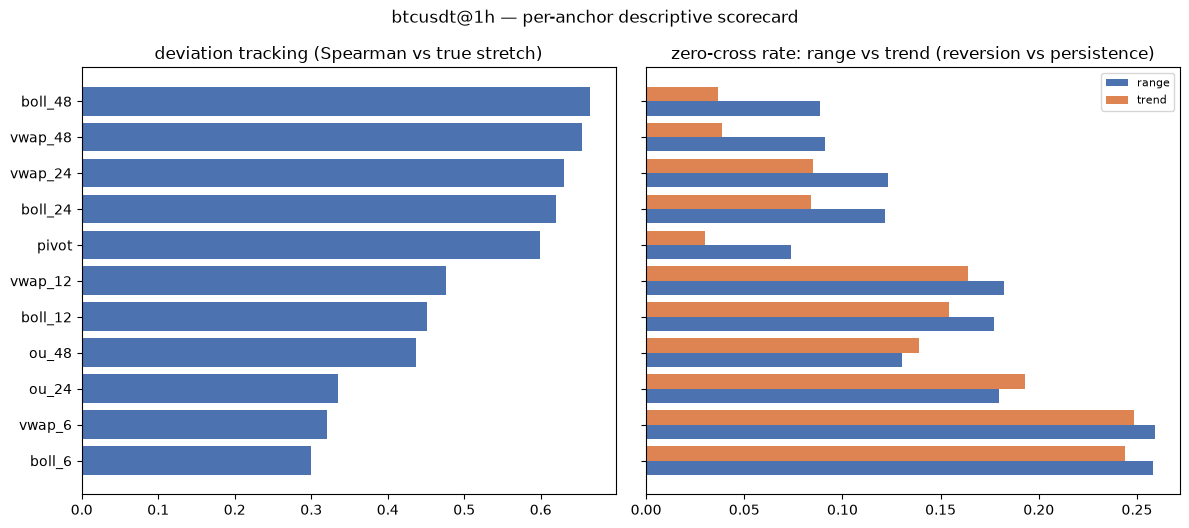

In [5]:
D.plot_scorecard(scores, f"{SPEC['label']} — per-anchor descriptive scorecard")

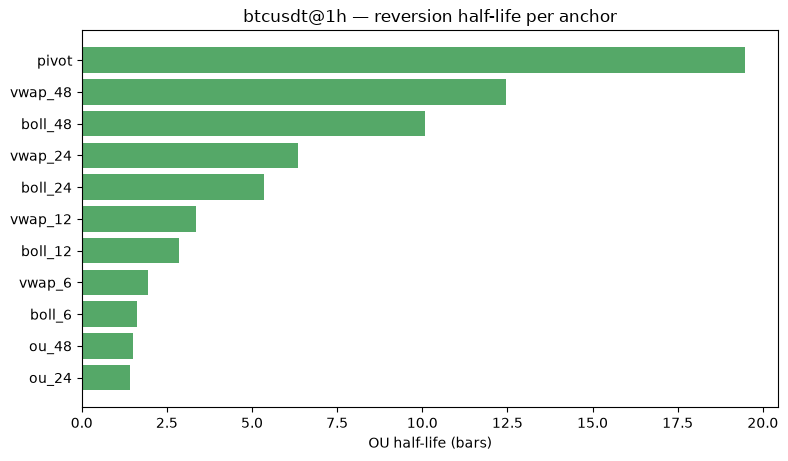

In [6]:
D.plot_halflife(scores, f"{SPEC['label']} — reversion half-life per anchor")

**What this shows.** Half-life rises with the window (a 48h Bollinger reverts over ~10h, a 6h one in ~1.6h). `dev_corr` rises with the window too — but only because the reference stretch is itself slow. The metric that actually answers *'does extreme z mark a turn'* is the reversal-tail check next, and it's matched to the ~8h horizon.

## Step 3b — Is the deviation *calibrated*? (distribution stability + reversal tails)

`dev_corr` says the z points the right way, but two things decide whether it's a trustworthy reading:
- **Distribution stability** — does the z keep the *same scale* over time? If its rolling quantiles drift, a fixed `±2 = extreme` is meaningless and we must report a *rolling percentile* instead. (`z_std_cv` = how much the rolling std drifts; lower is better.)
- **Reversal tails (ex-post)** — at the bars where price *actually* reversed (hindsight local tops/bottoms), was the z in its **tail**? `tail_sep` ≈ mean z-percentile at tops − at bottoms (≈+1 ⇒ tops in the upper tail, bottoms in the lower); `rev_extremity` = mean `|z|`-percentile at reversals (>0.5 ⇒ reversals are more extreme than typical). This is the real test that 'extreme z' marks a turn.

In [7]:
cal = D.calibration_panel(panel, close, order=REV_ORDER, window=ZWIN)
cal.round(3).sort_values('tail_sep', ascending=False)

,tail_sep,rev_extremity,z_std_cv
vwap_6,0.794,0.794,0.072
boll_6,0.791,0.791,0.014
boll_12,0.779,0.780,0.023
vwap_12,0.736,0.737,0.061
boll_24,0.619,0.655,0.031
vwap_24,0.579,0.627,0.085
ou_24,0.456,0.603,0.051
boll_48,0.446,0.567,0.053
vwap_48,0.418,0.557,0.104
pivot,0.375,0.544,0.172


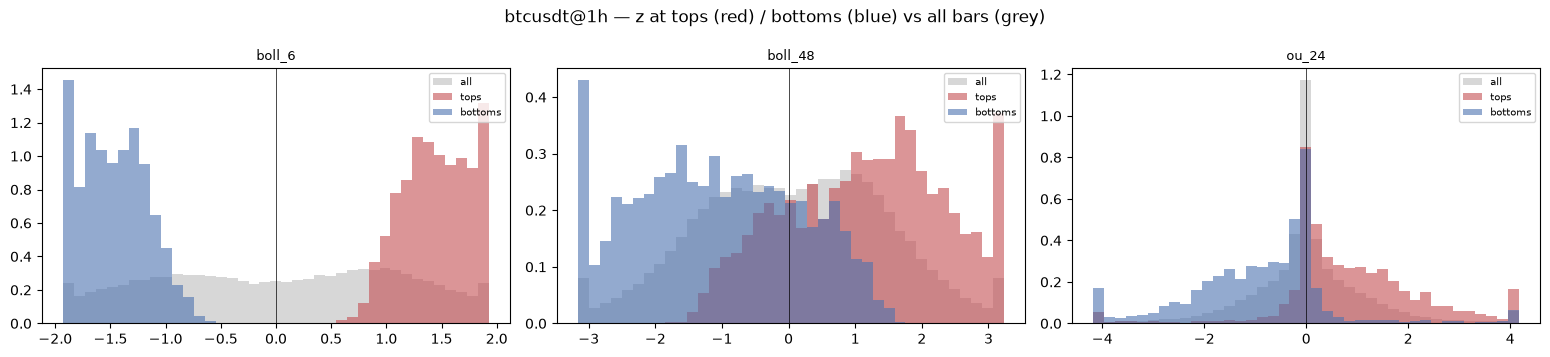

In [8]:
D.plot_reversal_tails(panel, close, ['boll_6', 'boll_48', 'ou_24'],
    f"{SPEC['label']} — z at tops (red) / bottoms (blue) vs all bars (grey)", order=REV_ORDER)

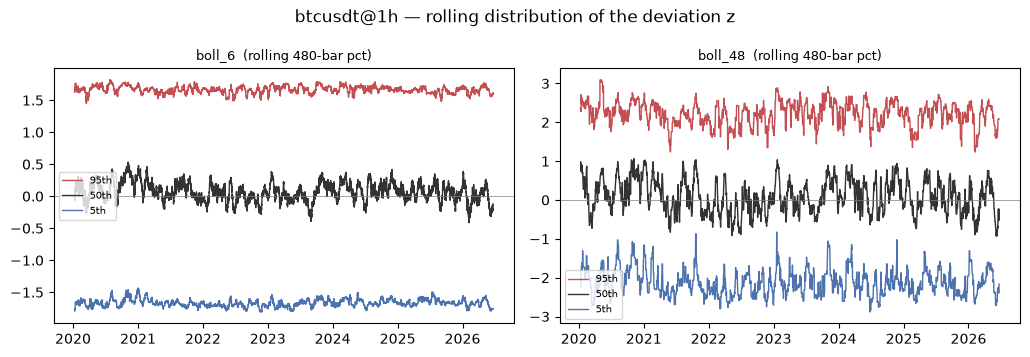

In [9]:
D.plot_z_stability(panel, ['boll_6', 'boll_48'],
    f"{SPEC['label']} — rolling distribution of the deviation z", window=ZWIN)

**What this shows — and it's the key result.** For ~8h reversals the **shortest anchors win decisively**: `boll_6`/`vwap_6`/`boll_12` put real tops in their upper tail and bottoms in their lower (high `tail_sep`) and are the most distribution-stable (`z_std_cv`≈0.01–0.02); the 48h Bollinger is **too slow** for an 8h turn and smears, and OU piles tops *and* bottoms near 0 (no tail calibration). This is **scale-matching**: the anchor window must match the reversal horizon you care about — the opposite ranking to `dev_corr` (which chased a slower reference). So at 1h we lead the tension with the **short (≈12h) Bollinger/VWAP**.

## Step 4 — Aggregate, or lead with the short window?

Collapse the panel into one **tension** descriptor — **`mean_z`** / **`median`** of the standardized deviations — and compare its calibration to the best single short anchor.

In [10]:
agg = D.aggregates(panel, window=ZWIN)
D.calibration_panel(agg, close, order=REV_ORDER, window=ZWIN).round(3)

,tail_sep,rev_extremity,z_std_cv
mean_z,0.695,0.700,0.040
median,0.666,0.686,0.038


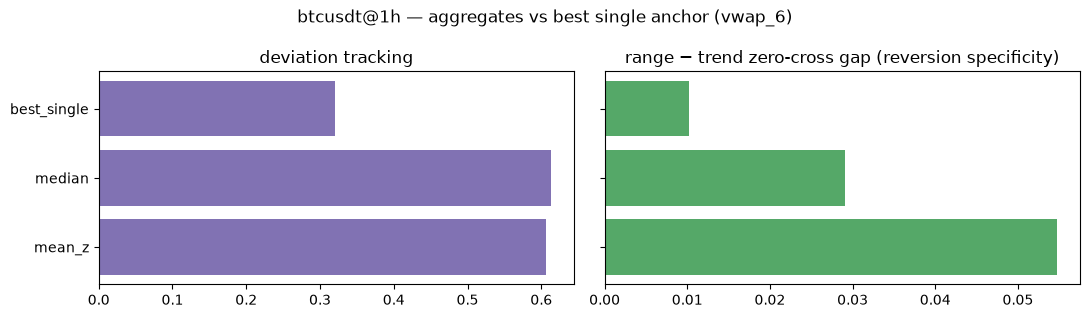

In [11]:
best = cal['tail_sep'].idxmax()
agg_scores = D.score_panel(agg, ref)
D.plot_aggregate_comparison(agg_scores, scores.loc[best],
    f"{SPEC['label']} — aggregates vs best single anchor ({best})")

**What this shows.** The flat aggregate mixes in the slow/uncalibrated anchors, so its reversal-tail calibration sits **below the best short anchor**. Unlike trend (where aggregation won), MR is better served by **leading with the short window**. So the reported `tension` is the short (≈12h) Bollinger/VWAP deviation, not a flat average.

## Step 5 — What we report for the universe scan

The causal reading we surface per instrument (`src.signals.state.mean_reversion_state`) is **short-window-led** (justified by Step 3b): the **tension** (signed ~12h Bollinger/VWAP deviation), its **historical percentile** (*how unusually stretched right now* — the drift-robust, comparable scale), the **stretch direction** (rich/cheap), whether it is **reverting** (range regime, so the tension is meaningful), and the current **half-life** in hours. Current snapshot:

In [12]:
live = state.current_state(
    state.mean_reversion_state(ohlc, tension_window=12, ou_window=48, er_window=48,
                               pct_window=2160), key='tension')
print(f"as of {close.index.max().date()}")
print(f"  reverting (range): {bool(live['reverting'])}   (ER {live['er']:.2f})")
print(f"  tension          : {live['tension']:+.2f}  "
      f"({'rich/above' if live['tension'] > 0 else 'cheap/below'} fair value)")
print(f"  |tension| %ile   : {live['tension_pct']:.0%}  (vs own history)")
hl = live['half_life']
print(f"  half-life        : {hl:.1f} h" if hl == hl else "  half-life        : n/a")

as of 2026-06-21
  reverting (range): True   (ER 0.04)
  tension          : -2.86  (cheap/below fair value)
  |tension| %ile   : 99%  (vs own history)
  half-life        : 5.0 h


## Summary

Descriptive findings (mean-reversion at its proper **short horizon**, 1h bars):
1. **Match the anchor window to the reversal horizon.** For ~8h turns the **short (6–12h) Bollinger/VWAP** are decisively best calibrated — real reversals land in their tails (`tail_sep`≈0.79) and their distribution is the most stable (`z_std_cv`≈0.01–0.02); slow anchors (48h) are too sluggish and OU has no tail calibration at all.
2. `dev_corr` ranked the *slow* anchors first, but only because it measured a slower reference deviation — the **reversal-tail check is the metric that matters**, and it (with the flat aggregate being diluted) says **lead with the short window**.
3. The scan line is **tension (≈12h, signed) + historical percentile + rich/cheap + reverting-flag + half-life (h)** — a compact MR state, comparable across instruments.

> Descriptive — *characterizes the current mean-reversion state, not tradeability.*

*Next:* run this on the rest of the universe (es1, nq1, eth) at 1h, add the MR tension line to the universe scan, then repeat the pattern for support/resistance.